# 02 · Data Understanding — inventory, EDA and data-quality audit
**Phase 2 (Skill 2 – identify, collect and store data)** · NextDeal for BH Assurance

Goals of this notebook
1. Inventory every data source (structured, semi-structured, unstructured) and where it is stored.
2. Describe the two analytical datasets and their granularity.
3. Explore them visually and extract business insights.
4. Audit data quality (missing values, hidden placeholders, outliers, duplicates, **leakage**).

All figures are written to `../figures/` and reused in the presentation.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import json
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import roc_auc_score

from src.utils import (RAW, ROOT, set_style, save, subtitle, PALETTE, INK, INK_2, INK_3, GRID,
                       SEQ_BLUE, normalize_label, split_multi)

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
BLUE, ORANGE, GREEN = PALETTE[0], PALETTE[1], PALETTE[2]

## 1. Data inventory

| # | Source | Type | Format / storage | Volume (this extract) | Used for |
|---|---|---|---|---|---|
| A | Corporate (PM) product portfolio + candidate products | **Structured** | CSV (`;`) → analytical store | 1,842 rows × 12 cols · 299 companies | cross-sell propensity (DSO1.x) |
| B | Individual (PP) contracts reaching expiry | **Semi-structured** | JSON documents (API / MongoDB) | 320 contracts × 21 fields | renewal & payment agent (DSO2.x) |
| C | Opportunity API samples (recommend / invoice / renewal × PM/PP) | **Semi-structured** | JSON (FastAPI responses) | 5 endpoint samples | agent tool contract (DSO1.3, 2.3) |
| D | Client e-mails & conversation history | **Unstructured** text | MongoDB (`conversations`, `messages`) | live stream | intent analysis (DSO3.1) |
| E | General conditions per line (CG-Vie, CG-Auto, CG-IARD, CG-Santé, CG-Transport, CG-Engineering) | **Unstructured** documents | PDF → chunks + embeddings in ChromaDB | 6 document families | RAG (DSO3.2) |

Sources A–C are analysed below. D and E feed the NLP/agentic DSOs and are collected by the
prototype's pipelines (Gmail API → MongoDB, PDF parser → ChromaDB); they are documented here
for completeness and will be profiled in the next milestone.

## 2. Dataset A — corporate product portfolio (`pm_product_portfolio.csv`)

In [2]:
pm = pd.read_csv(RAW / "pm_product_portfolio.csv", sep=";", encoding="utf-8-sig")
print(pm.shape)
pm.head()

(1842, 12)


,REF_pm,LIB_SECTEUR_ACTIVITE,LIB_ACTIVITE,LIB_PRODUIT,BRANCHE,LIB_SOUS_BRANCHE,age_contract,category,candidate_product,Bought,score,email
0,101372,COMMERCE DE GROS ET INTERMÉDIAIRES DU COMMERCE,AUTRES INTERMÉDIAIRES SPÉCIALISÉS DU COMMERCE,MULTIRISQUES PROFESSIONNELLES CENTRALISE,INCENDIE,MULTIRISQUES PROFESSIONNELLES,0.0,Commerce & Services,MULTIRISQUES PROFESSIONNELLES CENTRALISE,1,1.000000,ahmed10@gmail.com
1,101372,COMMERCE DE GROS ET INTERMÉDIAIRES DU COMMERCE,AUTRES INTERMÉDIAIRES SPÉCIALISÉS DU COMMERCE,MULTIRISQUES PROFESSIONNELLES CENTRALISE,INCENDIE,MULTIRISQUES PROFESSIONNELLES,0.0,Commerce & Services,MULTIRISQUES PROFESSIONNELLES,0,0.119682,ahmed10@gmail.com
2,101372,COMMERCE DE GROS ET INTERMÉDIAIRES DU COMMERCE,AUTRES INTERMÉDIAIRES SPÉCIALISÉS DU COMMERCE,MULTIRISQUES PROFESSIONNELLES CENTRALISE,INCENDIE,MULTIRISQUES PROFESSIONNELLES,0.0,Commerce & Services,AUTOMOBILE LEASING,0,0.108957,ahmed10@gmail.com
3,101372,COMMERCE DE GROS ET INTERMÉDIAIRES DU COMMERCE,AUTRES INTERMÉDIAIRES SPÉCIALISÉS DU COMMERCE,MULTIRISQUES PROFESSIONNELLES CENTRALISE,INCENDIE,MULTIRISQUES PROFESSIONNELLES,0.0,Commerce & Services,INCENDIE COMMERCIAL / LEASING,0,0.094341,ahmed10@gmail.com
4,101372,COMMERCE DE GROS ET INTERMÉDIAIRES DU COMMERCE,AUTRES INTERMÉDIAIRES SPÉCIALISÉS DU COMMERCE,MULTIRISQUES PROFESSIONNELLES CENTRALISE,INCENDIE,MULTIRISQUES PROFESSIONNELLES,0.0,Commerce & Services,AUTOMOBILE,0,0.000000,ahmed10@gmail.com


In [3]:
pm.dtypes.astype(str).to_frame("dtype").T

,REF_pm,LIB_SECTEUR_ACTIVITE,LIB_ACTIVITE,LIB_PRODUIT,BRANCHE,LIB_SOUS_BRANCHE,age_contract,category,candidate_product,Bought,score,email
dtype,int64,str,str,str,str,str,float64,str,str,int64,float64,str


### 2.1 Granularity and data dictionary
One row = **(company `REF_pm`, product currently held `LIB_PRODUIT`, candidate product `candidate_product`)**.
The prototype generated, for every product held, a short list of candidate products and a
CatBoost `score`. `Bought = 1` marks candidates the client already owns.

In [4]:
dictionary = pd.DataFrame({
    "column": pm.columns,
    "description": [
        "Pseudonymised company id",
        "Activity sector (≈ NACE section, French label)",
        "Detailed activity",
        "Product currently held",
        "Insurance line (branch) of the held product",
        "Sub-branch of the held product",
        "Age of the held contract (years)",
        "Business category grouping the sector (8 groups)",
        "Candidate product evaluated for this client",
        "1 if the client owns the candidate product",
        "Prototype CatBoost score for the candidate",
        "Contact e-mail (pseudonymised)",
    ],
    "role": ["key", "feature", "feature", "feature", "feature", "feature", "feature", "feature",
             "item", "target", "model output", "PII"],
    "n_unique": pm.nunique().values,
    "missing_%": (pm.isna().mean() * 100).round(1).values,
})
dictionary

,column,description,role,n_unique,missing_%
0,REF_pm,Pseudonymised company id,key,299,0.0
1,LIB_SECTEUR_ACTIVITE,"Activity sector (≈ NACE section, French label)",feature,47,9.2
2,LIB_ACTIVITE,Detailed activity,feature,141,0.4
3,LIB_PRODUIT,Product currently held,feature,34,0.0
4,BRANCHE,Insurance line (branch) of the held product,feature,7,0.0
5,LIB_SOUS_BRANCHE,Sub-branch of the held product,feature,19,0.0
6,age_contract,Age of the held contract (years),feature,7,0.0
7,category,Business category grouping the sector (8 groups),feature,8,0.0
8,candidate_product,Candidate product evaluated for this client,item,46,0.0
9,Bought,1 if the client owns the candidate product,target,2,0.0


In [5]:
summary = pd.Series({
    "rows": len(pm),
    "companies": pm["REF_pm"].nunique(),
    "held products (distinct)": pm["LIB_PRODUIT"].nunique(),
    "candidate products (distinct)": pm["candidate_product"].nunique(),
    "branches": pm["BRANCHE"].nunique(),
    "sectors": pm["LIB_SECTEUR_ACTIVITE"].nunique(),
    "activities": pm["LIB_ACTIVITE"].nunique(),
    "rows per company (median)": pm.groupby("REF_pm").size().median(),
    "positive rate Bought": round(pm["Bought"].mean(), 3),
    "exact duplicate rows": int(pm.duplicated().sum()),
    "distinct e-mails": pm["email"].nunique(),
})
summary.to_frame("value")

,value
rows,1842.000
companies,299.000
held products (distinct),34.000
candidate products (distinct),46.000
branches,7.000
sectors,47.000
activities,141.000
rows per company (median),5.000
positive rate Bought,0.244
exact duplicate rows,0.000


### 2.2 Missing values — explicit and hidden
Besides real `NaN`, some text columns hold **placeholders** such as `NON DEFINI`
("not defined") that are missing values in disguise.

In [6]:
explicit = pm.isna().sum()
hidden = pm.apply(lambda s: s.map(lambda v: isinstance(v, str) and pd.isna(normalize_label(v))).sum()
                  if s.dtype != "float64" and s.dtype != "int64" else 0)
missing = pd.DataFrame({"explicit NaN": explicit, "hidden placeholder": hidden})
missing["total_%"] = ((missing.sum(axis=1)) / len(pm) * 100).round(1)
missing = missing.sort_values("total_%", ascending=False)
missing[missing["total_%"] > 0]

,explicit NaN,hidden placeholder,total_%
LIB_SECTEUR_ACTIVITE,170,0,9.2
LIB_ACTIVITE,8,153,8.7


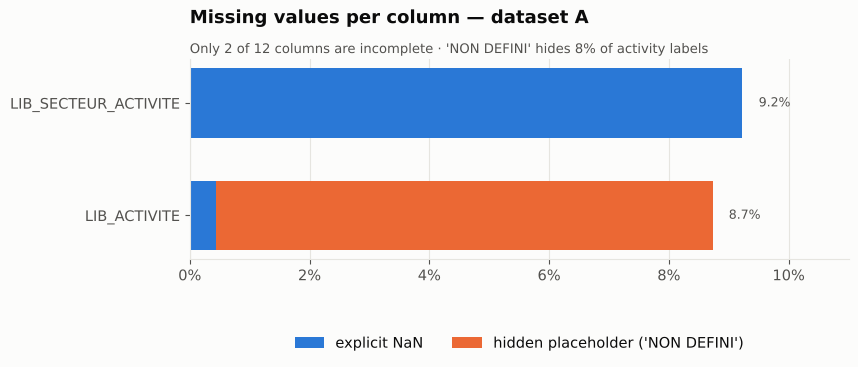

In [7]:
m = missing[missing["total_%"] > 0].sort_values("total_%")
fig, ax = plt.subplots(figsize=(8.5, 2.6))
y = np.arange(len(m))
ax.barh(y, m["explicit NaN"] / len(pm) * 100, color=BLUE, height=0.62, label="explicit NaN")
ax.barh(y, m["hidden placeholder"] / len(pm) * 100, left=m["explicit NaN"] / len(pm) * 100,
        color=ORANGE, height=0.62, label="hidden placeholder ('NON DEFINI')")
ax.set_yticks(y, m.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for yi, v in zip(y, m["total_%"]):
    if v > 0:
        ax.text(v + 0.3, yi, f"{v:.1f}%", va="center", fontsize=9, color=INK_2)
ax.set_title("Missing values per column — dataset A", pad=26)
subtitle(ax, f"Only 2 of 12 columns are incomplete · 'NON DEFINI' hides 8% of activity labels")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
ax.set_xlim(0, 11)
ax.grid(axis="y", visible=False)
save(fig, "fig01_pm_missing")
plt.show()

### 2.3 Portfolio depth — the core business insight
We rebuild the **set of products held by each company** (one company = one portfolio).

In [8]:
portfolio = pm.groupby("REF_pm")["LIB_PRODUIT"].apply(lambda s: sorted(set(s)))
n_products = portfolio.str.len()
depth = n_products.value_counts().sort_index()
print(f"Average products per company: {n_products.mean():.2f} · mono-product share: {(n_products == 1).mean():.1%}")
depth.to_frame("companies").T

Average products per company: 1.47 · mono-product share: 69.2%


LIB_PRODUIT,1,2,3,4,5,7
companies,207,60,21,7,3,1


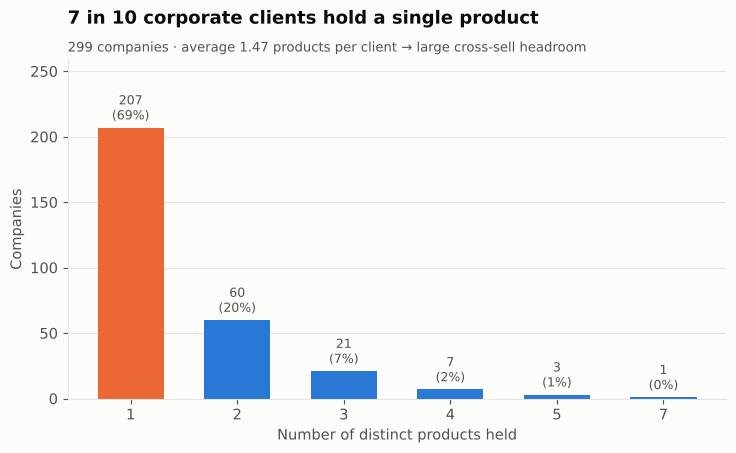

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
colors = [ORANGE if k == 1 else BLUE for k in depth.index]
bars = ax.bar(depth.index.astype(str), depth.values, color=colors, width=0.62)
for b, v in zip(bars, depth.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 3, f"{v}\n({v / depth.sum():.0%})", ha="center",
            va="bottom", fontsize=9, color=INK_2)
ax.set_ylim(0, depth.max() * 1.25)
ax.set_xlabel("Number of distinct products held")
ax.set_ylabel("Companies")
ax.set_title("7 in 10 corporate clients hold a single product", pad=26)
subtitle(ax, f"299 companies · average {n_products.mean():.2f} products per client → large cross-sell headroom")
ax.grid(axis="x", visible=False)
save(fig, "fig02_pm_products_per_client")
plt.show()

### 2.4 Which products and lines dominate?

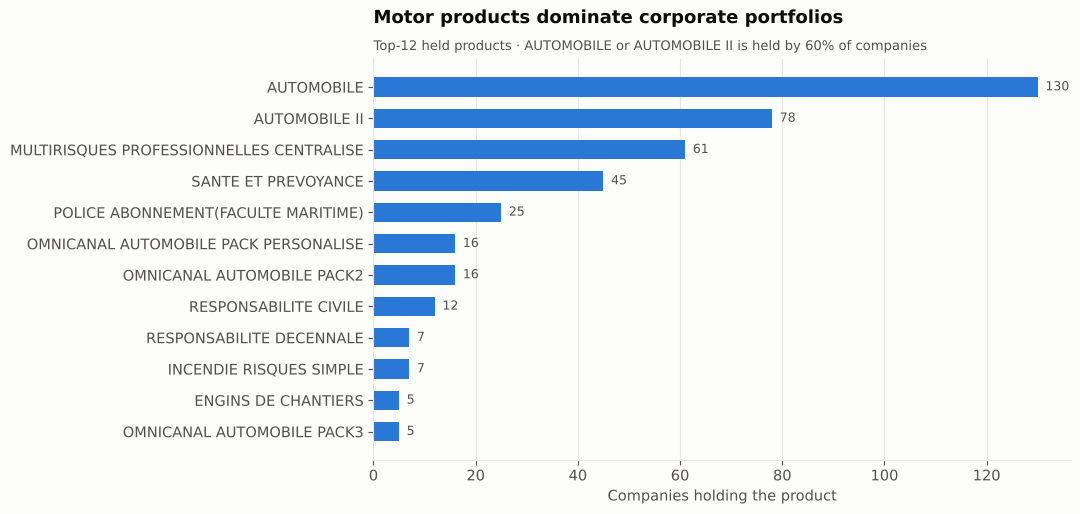

In [10]:
held = pm[["REF_pm", "LIB_PRODUIT", "BRANCHE"]].drop_duplicates()
by_branch = held.groupby("BRANCHE")["REF_pm"].nunique().sort_values()
top_products = held.groupby("LIB_PRODUIT")["REF_pm"].nunique().sort_values().tail(12)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top_products.index, top_products.values, color=BLUE, height=0.62)
for i, v in enumerate(top_products.values):
    ax.text(v + 1.5, i, str(v), va="center", fontsize=9, color=INK_2)
ax.set_xlabel("Companies holding the product")
ax.set_title("Motor products dominate corporate portfolios", pad=26)
motor_share = portfolio.map(lambda p: bool({"AUTOMOBILE", "AUTOMOBILE II"} & set(p))).mean()
subtitle(ax, f"Top-12 held products · AUTOMOBILE or AUTOMOBILE II is held by {motor_share:.0%} of companies")
ax.grid(axis="y", visible=False)
save(fig, "fig03_pm_top_products")
plt.show()

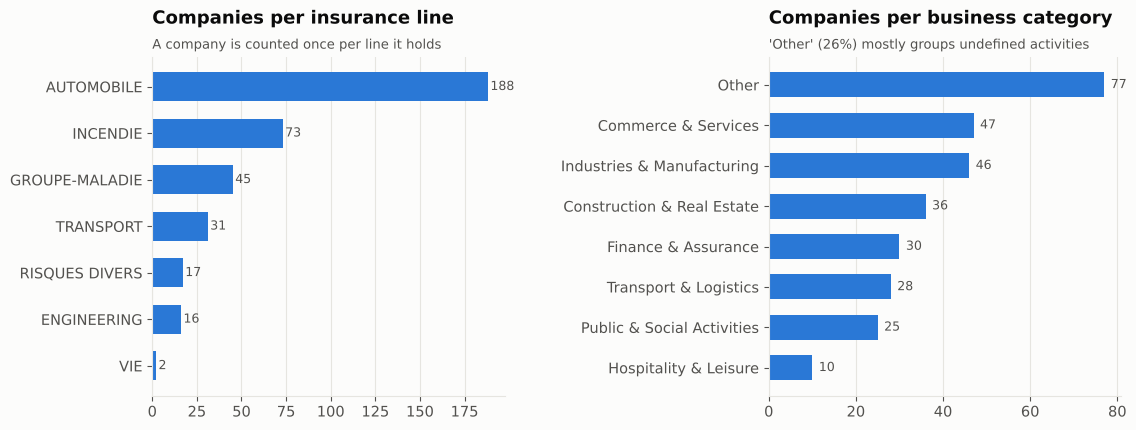

In [11]:
cats = pm.groupby("REF_pm")["category"].first().value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"wspace": 0.75})
for ax, series, title, sub in [
    (axes[0], by_branch, "Companies per insurance line", "A company is counted once per line it holds"),
    (axes[1], cats, "Companies per business category", "'Other' (26%) mostly groups undefined activities"),
]:
    ax.barh(series.index, series.values, color=BLUE, height=0.62)
    for i, v in enumerate(series.values):
        ax.text(v + 1.5, i, str(v), va="center", fontsize=9, color=INK_2)
    ax.set_title(title, pad=24)
    subtitle(ax, sub)
    ax.grid(axis="y", visible=False)
save(fig, "fig04_pm_branches_categories")
plt.show()

### 2.5 Which products are held together? (co-ownership)
Co-ownership counts are the raw material of item-based recommendation: if many companies
that hold *X* also hold *Y*, *Y* is a natural next product for X-only clients.

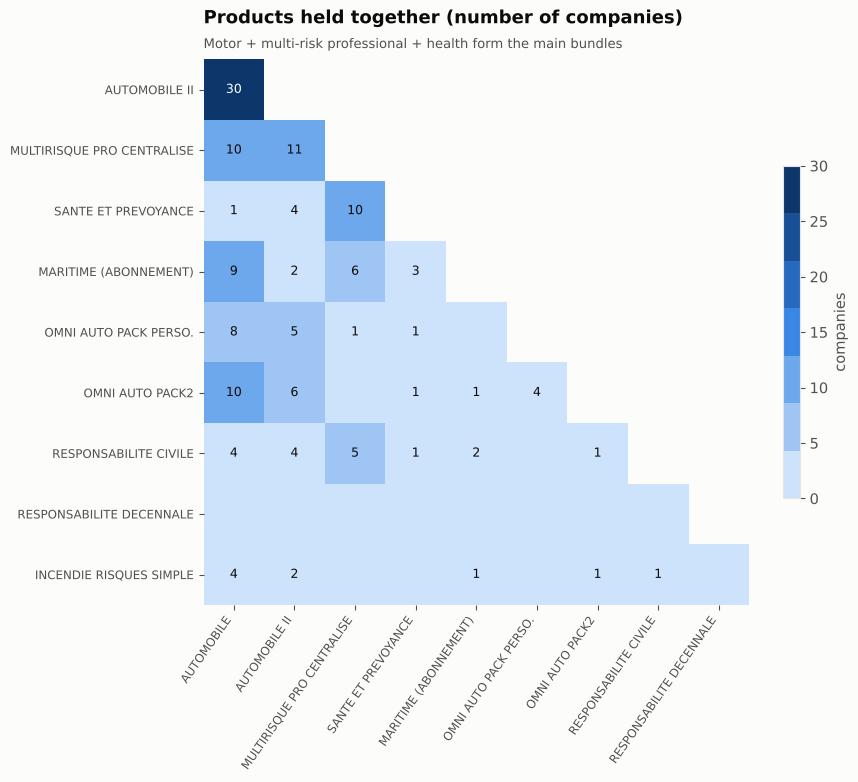

In [12]:
top10 = held.groupby("LIB_PRODUIT")["REF_pm"].nunique().sort_values(ascending=False).head(10).index
pair_counts = Counter()
for prods in portfolio:
    for a, b in combinations(sorted(set(prods) & set(top10)), 2):
        pair_counts[(a, b)] += 1
co = pd.DataFrame(0, index=top10, columns=top10)
for (a, b), c in pair_counts.items():
    co.loc[a, b] = co.loc[b, a] = c
ABBREV = {"OMNICANAL AUTOMOBILE ": "OMNI AUTO ", "MULTIRISQUES PROFESSIONNELLES": "MULTIRISQUE PRO",
          "POLICE ABONNEMENT(FACULTE MARITIME)": "MARITIME (ABONNEMENT)", "PERSONALISE": "PERSO."}
def abbreviate(p):
    for k, v in ABBREV.items():
        p = p.replace(k, v)
    return p
short = {p: abbreviate(p) for p in top10}

fig, ax = plt.subplots(figsize=(8.8, 7.2))
co = co.iloc[1:, :-1]   # drop the empty first row / last column of the lower triangle
mask = np.triu(np.ones_like(co, dtype=bool), k=1)
data = np.ma.masked_array(co.values, mask)
from matplotlib.colors import ListedColormap
cmap = ListedColormap(SEQ_BLUE)
cmap.set_bad(alpha=0)
im = ax.imshow(data, cmap=cmap, vmin=0, vmax=max(co.values.max(), 1))
for i in range(co.shape[0]):
    for j in range(i + 1):
        v = co.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=9, color="white" if v > 12 else INK)
ax.set_xticks(range(len(co)), [short[p] for p in co.columns], rotation=55, ha="right", fontsize=8.5)
ax.set_yticks(range(len(co)), [short[p] for p in co.index], fontsize=8.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Products held together (number of companies)", pad=26)
subtitle(ax, "Motor + multi-risk professional + health form the main bundles")
fig.colorbar(im, ax=ax, shrink=0.6, label="companies")
save(fig, "fig05_pm_cooccurrence")
plt.show()

### 2.6 Contract age and outliers

{'count': 450.0, 'mean': 0.36, 'std': 1.57, 'min': 0.0, '25%': 0.0, '50%': 0.0, '75%': 0.0, 'max': 10.0}
IQR fence = 0.0 → every non-zero age is a 'statistical outlier' (10% of contracts)


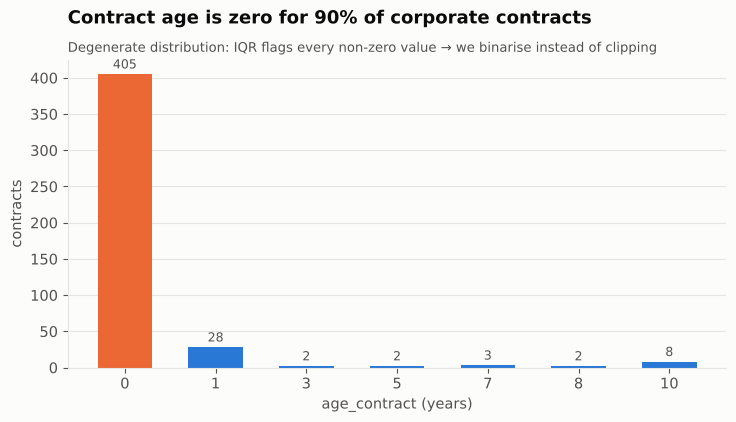

In [13]:
ages = pm.drop_duplicates(["REF_pm", "LIB_PRODUIT", "age_contract"])["age_contract"]
q1, q3 = ages.quantile([0.25, 0.75])
print(ages.describe().round(2).to_dict())
print(f"IQR fence = {q3 + 1.5 * (q3 - q1):.1f} → every non-zero age is a 'statistical outlier' "
      f"({(ages > 0).mean():.0%} of contracts)")

fig, ax = plt.subplots(figsize=(8.5, 4))
vc = ages.value_counts().sort_index()
ax.bar(vc.index.astype(int).astype(str), vc.values, color=[ORANGE if k == 0 else BLUE for k in vc.index], width=0.6)
for i, v in enumerate(vc.values):
    ax.text(i, v + 8, str(v), ha="center", fontsize=9, color=INK_2)
ax.set_xlabel("age_contract (years)")
ax.set_ylabel("contracts")
ax.set_title(f"Contract age is zero for {(ages == 0).mean():.0%} of corporate contracts", pad=26)
subtitle(ax, "Degenerate distribution: IQR flags every non-zero value → we binarise instead of clipping")
ax.grid(axis="x", visible=False)
save(fig, "fig06_pm_age_contract")
plt.show()

### 2.7 Leakage check on the prototype score ⚠️
The prototype reports a CatBoost `score` for every (client, candidate) pair. Before reusing it
we check **how the target is built**.

In [14]:
same = pm["candidate_product"] == pm["LIB_PRODUIT"]
print("Bought == (candidate_product == LIB_PRODUIT):", bool((same.astype(int) == pm["Bought"]).all()))
print(f"ROC-AUC of the stored score: {roc_auc_score(pm['Bought'], pm['score']):.3f}")
pm.groupby("Bought")["score"].describe().round(3)

Bought == (candidate_product == LIB_PRODUIT): True
ROC-AUC of the stored score: 0.997


,count,mean,std,min,25%,50%,75%,max
Bought,,,,,,,,
0,1392.0,0.056,0.068,0.0,0.000,0.025,0.101,0.328
1,450.0,0.968,0.094,0.0,0.985,1.000,1.000,1.000


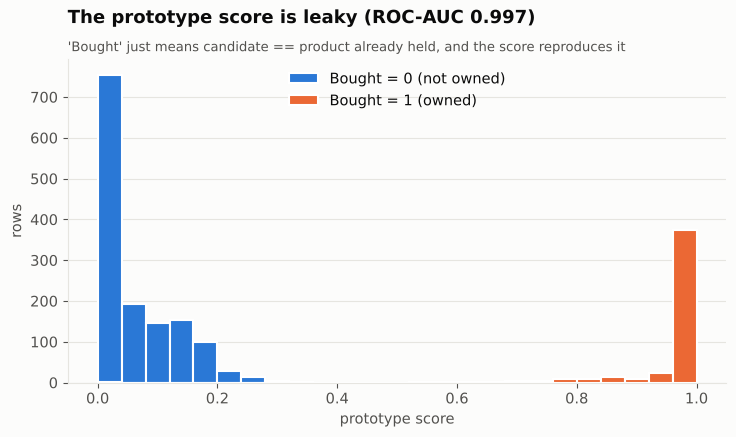

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bins = np.linspace(0, 1, 26)
ax.hist(pm.loc[pm.Bought == 0, "score"], bins=bins, color=BLUE, label="Bought = 0 (not owned)",
        edgecolor="white", linewidth=1.5)
ax.hist(pm.loc[pm.Bought == 1, "score"], bins=bins, color=ORANGE, label="Bought = 1 (owned)",
        edgecolor="white", linewidth=1.5)
ax.set_xlabel("prototype score")
ax.set_ylabel("rows")
ax.legend(loc="upper center")
ax.set_title("The prototype score is leaky (ROC-AUC 0.997)", pad=26)
subtitle(ax, "'Bought' just means candidate == product already held, and the score reproduces it")
ax.grid(axis="x", visible=False)
save(fig, "fig07_pm_leakage")
plt.show()

**Conclusion:** `Bought` only says *"the candidate is the product already held"*, and the score
separates the classes almost perfectly because the model saw that information. The 0.997 AUC
is **not** a cross-sell performance. In notebook 03 we rebuild an honest target: *hide one
product the company owns and ask the model to find it from the rest of the profile.*

## 3. Dataset B — individual contracts reaching expiry (`pp_contract_renewals.json`)

In [16]:
raw_pp = json.loads((RAW / "pp_contract_renewals.json").read_text())
print(type(raw_pp), len(raw_pp), "documents · keys of one document:", list(raw_pp[0]), "→ nested 'profile'")
pp = pd.json_normalize(raw_pp)
pp.columns = [c.replace("profile.", "") for c in pp.columns]
print(pp.shape)
pp.head(3)

<class 'list'> 320 documents · keys of one document: ['user_id', 'profile', 'decision'] → nested 'profile'
(320, 21)


,user_id,decision,Num_Piece_Identite,Situation_Familiale,Lib_Secteur_Activite,Lib_Profession,Age_Contrat,LIB_PRODUIT,Category,Candidate_Produit,Decision,statut_paiement,Effet_Contrat,Date_Expiration,Num_Contrat,Lib_Garantie,LIB_BRANCHE,LIB_SOUS_BRANCHE,Age,nb_sinistres_2025,Candidate_Garanties
0,13695,renouvellement contrat,10000470,Marie,NaN,NaN,1.0,AUTOMOBILE II,Non défini,AUTOMOBILE;AUTOMOBILE II;AUTOMOBILE LEASING;AUTOMOBILE A...,renouvellement contrat,Non payé,2024-09-17,2025-09-16,2.024301e+12,RC - RTI;DEFENSE ET RECOURS,AUTOMOBILE,AUTOMOBILE,0,54.0,ASSISTANCE ACCIDENT AUTOMOBILE (3A);EMEUTE ET MOUVEMENT ...
1,13695,renouvellement contrat,10000470,Marie,NaN,NaN,1.0,AUTOMOBILE II,Non défini,AUTOMOBILE;AUTOMOBILE II;AUTOMOBILE LEASING;AUTOMOBILE A...,renouvellement contrat,Payé,2024-09-17,2025-09-16,2.024301e+12,RC - RTI;DEFENSE ET RECOURS;INCENDIE;CATASTROPHE NATUREL...,AUTOMOBILE,AUTOMOBILE,0,54.0,ASSISTANCE +;ASSISTANCE GOLD;CHOC DE VEHICULES TERRESTRE...
2,23616,renouvellement contrat,10001817,Marie,OUVRIERS,CONDUCTEURS DE VÉHICULE ROUTIER DE TRANSPORT EN COMMUN (...,1.0,AUTOMOBILE,Professions & Métiers,TEMPORAIRE DECES;TEMPORAIRE DECES A CAPITAL DECROISSANT ...,renouvellement contrat,Payé,2024-09-25,2025-09-24,2.024301e+12,RC - RTI;DEFENSE ET RECOURS;INCENDIE;P.T.A;CATASTROPHE N...,AUTOMOBILE,AUTOMOBILE,0,75.0,ACCIDENT CARE;CAR GLASS;DOMMAGES AU VEHICULE


In [17]:
pp_summary = pd.DataFrame({
    "dtype": pp.dtypes.astype(str),
    "n_unique": pp.nunique(),
    "missing": pp.isna().sum(),
    "example": pp.iloc[0].astype(str).str.slice(0, 45),
})
pp_summary

,dtype,n_unique,missing,example
user_id,int64,316,0,13695
decision,str,1,0,renouvellement contrat
Num_Piece_Identite,int64,316,0,10000470
Situation_Familiale,str,4,8,Marie
Lib_Secteur_Activite,str,18,34,NaN
Lib_Profession,str,89,24,NaN
Age_Contrat,float64,15,0,1.0
LIB_PRODUIT,str,14,0,AUTOMOBILE II
Category,str,11,0,Non défini
Candidate_Produit,str,52,0,AUTOMOBILE;AUTOMOBILE II;AUTOMOBILE LEASING;A


In [18]:
quality_pp = pd.Series({
    "documents": len(pp),
    "distinct clients (user_id)": pp["user_id"].nunique(),
    "duplicated user_id": int(pp["user_id"].duplicated().sum()),
    "constant columns": ", ".join(c for c in pp.columns if pp[c].nunique() <= 1) or "—",
    "Age == 0": f"{(pp['Age'] == 0).mean():.1%}",
    "nb_sinistres_2025 median": pp["nb_sinistres_2025"].median(),
    "unpaid contracts": int((pp["statut_paiement"] == "Non payé").sum()),
    "category 'Non classé' / 'Non défini'": int(pp["Category"].isin(["Non classé", "Non défini"]).sum()),
})
quality_pp.to_frame("value")

,value
documents,320
distinct clients (user_id),316
duplicated user_id,4
constant columns,"decision, Decision"
Age == 0,99.7%
nb_sinistres_2025 median,50.0
unpaid contracts,12
category 'Non classé' / 'Non défini',147


### 3.1 What expires, when, and is it paid?

Expiry window: 2025-09-01 → 2025-09-27 · 1 month(s)


statut_paiement,Payé,Non payé
contracts,308,12


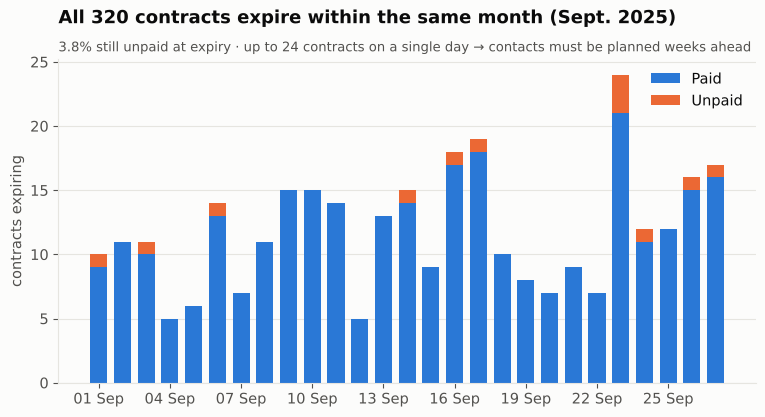

In [19]:
pp["Date_Expiration"] = pd.to_datetime(pp["Date_Expiration"], errors="coerce")
pp["Effet_Contrat"] = pd.to_datetime(pp["Effet_Contrat"], errors="coerce")
print("Expiry window:", pp["Date_Expiration"].min().date(), "→", pp["Date_Expiration"].max().date(),
      "·", pp["Date_Expiration"].dt.to_period("M").nunique(), "month(s)")
daily = (pp.pivot_table(index="Date_Expiration", columns="statut_paiement", values="Num_Contrat",
                        aggfunc="count", fill_value=0)
           .reindex(pd.date_range(pp["Date_Expiration"].min(), pp["Date_Expiration"].max()), fill_value=0))
daily = daily[[c for c in ["Payé", "Non payé"] if c in daily.columns]]
display(daily.sum().to_frame("contracts").T)

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(daily))
ax.bar(x, daily["Payé"], color=BLUE, width=0.72, label="Paid")
ax.bar(x, daily["Non payé"], bottom=daily["Payé"], color=ORANGE, width=0.72, label="Unpaid")
ax.set_xticks(x[::3], [d.strftime("%d %b") for d in daily.index[::3]])
ax.set_ylabel("contracts expiring")
ax.legend(loc="upper right")
ax.set_title("All 320 contracts expire within the same month (Sept. 2025)", pad=26)
subtitle(ax, f"{(pp.statut_paiement == 'Non payé').mean():.1%} still unpaid at expiry · up to {int(daily.sum(axis=1).max())} contracts on a single day → contacts must be planned weeks ahead")
ax.grid(axis="x", visible=False)
save(fig, "fig08_pp_expiry_timeline")
plt.show()

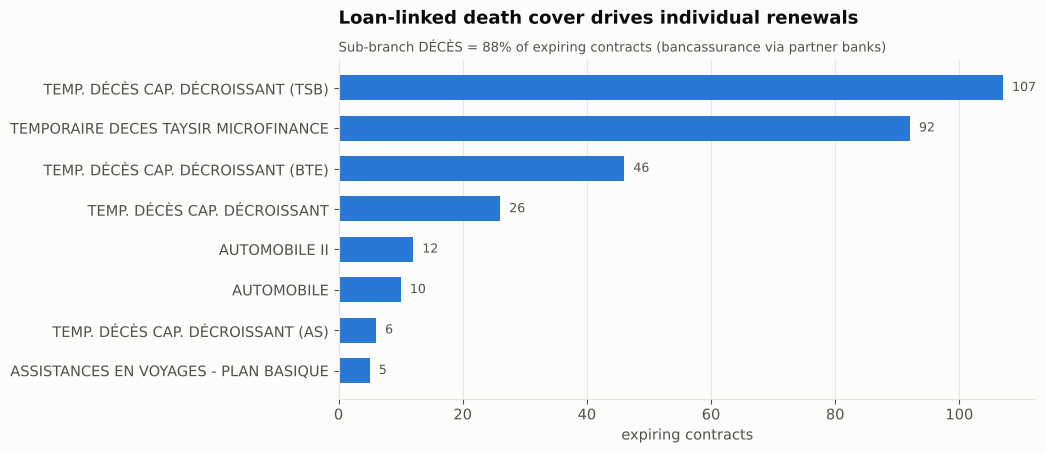

In [20]:
lines = pp["LIB_SOUS_BRANCHE"].value_counts()
prods = pp["LIB_PRODUIT"].map(lambda s: s.replace("TEMPORAIRE DECES A CAPITAL DECROISSANT LINEAIREMENT", "TEMP. DÉCÈS CAP. DÉCROISSANT")).value_counts().head(8).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(prods.index, prods.values, color=BLUE, height=0.62)
for i, v in enumerate(prods.values):
    ax.text(v + 1.5, i, str(v), va="center", fontsize=9, color=INK_2)
ax.set_xlabel("expiring contracts")
ax.set_title("Loan-linked death cover drives individual renewals", pad=26)
subtitle(ax, f"Sub-branch DÉCÈS = {lines.get('DECES', 0) / len(pp):.0%} of expiring contracts (bancassurance via partner banks)")
ax.grid(axis="y", visible=False)
save(fig, "fig09_pp_products")
plt.show()

### 3.2 Guarantees held and guarantees proposed (multi-valued fields)

Distinct candidate-guarantee lists: 34


,held,proposed
DECES - I.D.T,284,0
INCAPACITE,47,0
RC - RTI,27,0
DEFENSE ET RECOURS,27,0
INCENDIE,21,0
P.T.A,19,0
SALIM ASSISTANCE AUTOMOBILE (S2A),18,0
CATASTROPHE NATURELLE,16,0
DECES TRIPLEMENT,0,284
DECES DOUBLEMENT,0,284


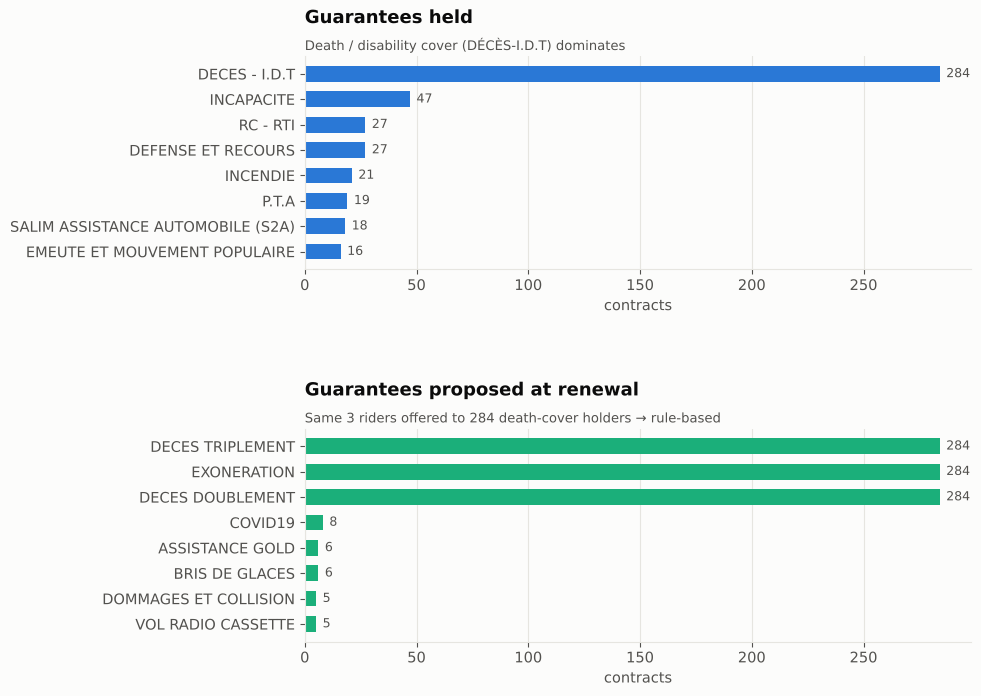

In [21]:
held_g = pd.Series(Counter(g for v in pp["Lib_Garantie"] for g in split_multi(v))).sort_values()
cand_g = pd.Series(Counter(g for v in pp["Candidate_Garanties"] for g in split_multi(v))).sort_values()
print("Distinct candidate-guarantee lists:", pp["Candidate_Garanties"].nunique())
display(pd.concat({"held": held_g.sort_values(ascending=False).head(8),
                   "proposed": cand_g.sort_values(ascending=False).head(8)}, axis=1).fillna(0).astype(int))

fig, axes = plt.subplots(2, 1, figsize=(8.6, 7.6), gridspec_kw={"hspace": 0.75})
for ax, series, color, title in [(axes[0], held_g.tail(8), BLUE, "Guarantees held"),
                                 (axes[1], cand_g.tail(8), GREEN, "Guarantees proposed at renewal")]:
    ax.barh([s_[:36] for s_ in series.index], series.values, color=color, height=0.62)
    for i, v in enumerate(series.values):
        ax.text(v + 3, i, str(v), va="center", fontsize=9, color=INK_2)
    ax.set_xlabel("contracts")
    ax.set_title(title, pad=24)
    ax.grid(axis="y", visible=False)
subtitle(axes[0], "Death / disability cover (DÉCÈS-I.D.T) dominates")
subtitle(axes[1], f"Same 3 riders offered to {cand_g.max()} death-cover holders → rule-based")
save(fig, "fig10_pp_guarantees")
plt.show()

### 3.3 Suspicious fields

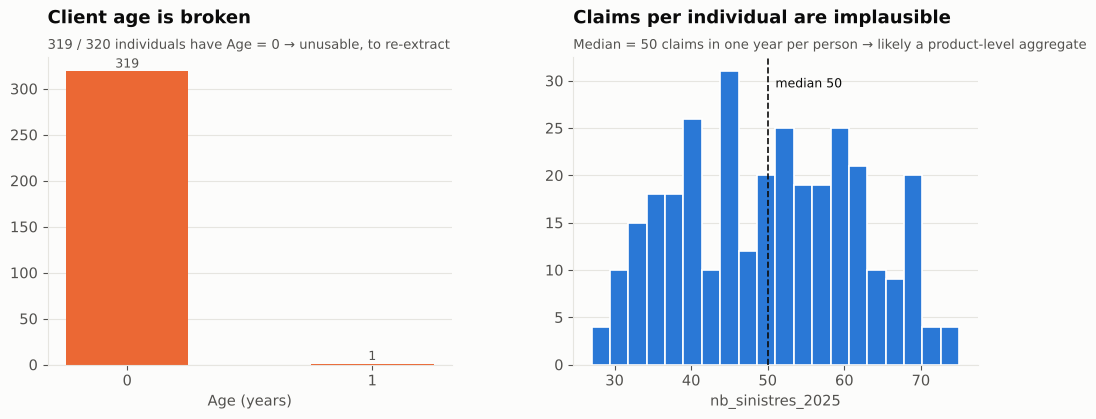

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"wspace": 0.3})
vc_age = pp["Age"].value_counts().sort_index()
axes[0].bar(vc_age.index.astype(str), vc_age.values, color=ORANGE, width=0.5)
for i, v in enumerate(vc_age.values):
    axes[0].text(i, v + 4, str(v), ha="center", fontsize=9, color=INK_2)
axes[0].set_xlabel("Age (years)")
axes[0].set_title("Client age is broken", pad=24)
subtitle(axes[0], "319 / 320 individuals have Age = 0 → unusable, to re-extract")
axes[1].hist(pp["nb_sinistres_2025"], bins=20, color=BLUE, edgecolor="white", linewidth=1.2)
axes[1].axvline(pp["nb_sinistres_2025"].median(), color=INK, lw=1.2, ls="--")
axes[1].text(pp["nb_sinistres_2025"].median() + 1, axes[1].get_ylim()[1] * 0.9,
             f"median {pp['nb_sinistres_2025'].median():.0f}", fontsize=9, color=INK)
axes[1].set_xlabel("nb_sinistres_2025")
axes[1].set_title("Claims per individual are implausible", pad=24)
subtitle(axes[1], f"Median = {pp['nb_sinistres_2025'].median():.0f} claims in one year per person → likely a product-level aggregate")
for a in axes:
    a.grid(axis="x", visible=False)
save(fig, "fig11_pp_suspicious_fields")
plt.show()

## 4. Dataset C — opportunity API samples (agent tool contract)
These JSON responses are what the agent receives when it calls the opportunity API. They fix
the **schema of the tools** our models must feed (e.g. `recommend_pm` must return a product and a score).

In [23]:
rows = []
for f in sorted((RAW / "api_samples").glob("*.json")):
    doc = json.loads(f.read_text())[0]
    prof = doc.get("profile", {})
    rows.append({
        "endpoint": f.stem,
        "strategy": doc.get("endpoint_strategy", doc.get("decision")),
        "action": doc.get("recommended_action", doc.get("decision")),
        "profile fields": len(prof),
        "example fields": ", ".join(list(prof)[:6]) + " …",
    })
pd.DataFrame(rows)

,endpoint,strategy,action,profile fields,example fields
0,facture_pm,payment_reminder,paiement_facture,32,"matricule_fiscale, lib_secteur_activite, lib_activite, l..."
1,facture_pp,payment_reminder,paiement_facture,29,"num_piece_identite, situation_familiale, lib_secteur_act..."
2,recommend_pm,product_recommendation,recommend_produit,24,"lib_secteur_activite, lib_activite, lib_produit, branche..."
3,recommend_pp,product_recommendation,recommend_produit,28,"recommended_product, recommended_score, status, situatio..."
4,renouvellement_pm,renouvellement contrat,renouvellement contrat,20,"MATRICULE_FISCALE, LIB_SECTEUR_ACTIVITE, LIB_ACTIVITE, L..."


## 5. Findings to carry into preparation and modeling

In [24]:
findings = pd.DataFrame([
    ["A", "Target leakage", "Bought ≡ (candidate == held product); stored score AUC 0.997", "Drop score/Bought as-is; rebuild a leave-one-out next-product target", "High"],
    ["A", "Missing values", "Sector NaN 9.2 %; activity 'NON DEFINI' 8.3 %", "Normalise placeholders → NaN; impute sector from activity, else 'UNKNOWN'", "Medium"],
    ["A", "Granularity", "Rows repeat the client profile for each candidate", "Aggregate to one row per company + multi-hot portfolio", "High"],
    ["A", "Outliers", "age_contract = 0 for 89 %; IQR fence = 0", "Binarise (has_history) + keep max age per product", "Low"],
    ["A", "PII / constant", "Single e-mail value for all rows", "Drop (no information, privacy)", "Low"],
    ["A", "Imbalance", "Mono-product clients = 69 %", "Ranking metrics (HitRate@k), client-grouped CV", "Medium"],
    ["B", "Broken field", "Age = 0 for 319/320 clients", "Exclude; request re-extraction", "Medium"],
    ["B", "Implausible values", "nb_sinistres_2025 median = 50 claims per individual", "Flag as unreliable; exclude from models until clarified", "Medium"],
    ["B", "Duplicates", "4 duplicated user_id (several contracts); 'decision' stored twice", "Keep: unit = contract; dedupe on Num_Contrat; drop constant columns", "Low"],
    ["B", "Generic proposals", "Same 3 riders proposed to 284 death-cover holders", "Personalise guarantee upsell (DSO2.2)", "Medium"],
    ["B", "Multi-valued text", "Guarantees stored as 'A;B;C' strings", "Split + multi-hot encode", "Medium"],
    ["B", "Rare target", "Only 12 unpaid contracts (3.8 %)", "Too few for a risk model → collect more history (DSO2.1)", "High"],
    ["B", "Hidden missing", "Category 'Non classé' / 'Non défini' = 46 %", "Map to UNKNOWN; rebuild category from sector", "Medium"],
], columns=["dataset", "issue", "evidence", "decision", "impact"])
findings.to_csv(ROOT / "reports" / "data_quality_findings.csv", index=False)
findings

,dataset,issue,evidence,decision,impact
0,A,Target leakage,Bought ≡ (candidate == held product); stored score AUC 0...,Drop score/Bought as-is; rebuild a leave-one-out next-pr...,High
1,A,Missing values,Sector NaN 9.2 %; activity 'NON DEFINI' 8.3 %,Normalise placeholders → NaN; impute sector from activit...,Medium
2,A,Granularity,Rows repeat the client profile for each candidate,Aggregate to one row per company + multi-hot portfolio,High
3,A,Outliers,age_contract = 0 for 89 %; IQR fence = 0,Binarise (has_history) + keep max age per product,Low
4,A,PII / constant,Single e-mail value for all rows,"Drop (no information, privacy)",Low
5,A,Imbalance,Mono-product clients = 69 %,"Ranking metrics (HitRate@k), client-grouped CV",Medium
6,B,Broken field,Age = 0 for 319/320 clients,Exclude; request re-extraction,Medium
7,B,Implausible values,nb_sinistres_2025 median = 50 claims per individual,Flag as unreliable; exclude from models until clarified,Medium
8,B,Duplicates,4 duplicated user_id (several contracts); 'decision' sto...,Keep: unit = contract; dedupe on Num_Contrat; drop const...,Low
9,B,Generic proposals,Same 3 riders proposed to 284 death-cover holders,Personalise guarantee upsell (DSO2.2),Medium
